# Atomity | Azure Cloud Workload — Exploratory Data Analysis

**Dataset:** Microsoft Azure Public Dataset V2 curated `data-v1` release.  
**Scope:** All aggregate and VM-level CPU summaries, figures, and decisions use only the **first 110 timestamps**. The final 24 target values are withheld from this notebook.

The source time column is **seconds relative to the original trace**, not a wall-clock timestamp. Do **not** interpret elapsed hours as time-of-day or calculate day-of-week effects.

> The script `python -m cwfc.eda --data challenge_data --output reports` reproduces this analysis without a notebook. Open `reports/eda_summary.md` for quantitative analysis and operational implications.

## 1 — Load the provided data and establish the holdout boundary

The loader creates the complete aggregate series as the assignment specifies, splits chronologically, and immediately discards holdout labels. All subsequent analysis sees training readings only.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

# Support notebook launches from the repository root or notebooks/ folder.
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / 'pyproject.toml').exists()), None)
if ROOT is None:
    raise RuntimeError('Run this notebook from the project root or notebooks/ directory')
sys.path.insert(0, str(ROOT / 'src'))
from cwfc.data import load_training_bundle
from cwfc.eda import compute_eda, write_eda

bundle = load_training_bundle(ROOT / 'challenge_data', train_steps=110, horizon=24)
print('Public source timestamps:', len(bundle.all_timestamps))
print('Training-only timestamps:', len(bundle.targets))
print('Holdout timestamp coordinates:', len(bundle.forecast_timestamps))
print('Training CPU observations:', len(bundle.readings))
print('Full-trace CPU statistics from metadata included:', any(
    x in bundle.metadata.columns for x in ['avg_cpu', 'max_cpu', 'p95_max_cpu', 'timestamp_vm_deleted']))

Public source timestamps: 134
Training-only timestamps: 110
Holdout timestamp coordinates: 24
Training CPU observations: 1100000
Full-trace CPU statistics from metadata included: False


## 2 — Data quality and required targets

Data integrity is necessary before fitting anything. We check sampling cadence, target ranges, VM coverage and temporal order. Churn is measured **only within the observed training cohort**.

In [2]:
stats, by_category_time, by_core = compute_eda(bundle)
print('Data audit:')
display(pd.Series(bundle.audit, name='value').to_frame())
print('Training aggregate targets (first and last five rows only):')
display(pd.concat([bundle.targets.head(5), bundle.targets.tail(5)]))
print('Training target summary:')
display(bundle.targets[['active_vm_count','aggregate_cpu_utilization']].describe())

Data audit:


,value
total_rows,1340000
unique_vms,10000
metadata_rows,10000
all_timestamp_count,134
training_timestamp_count,110
training_row_count,1100000
forecast_timestamp_count,24
cadence_seconds,300
training_missing_measurements,0
training_duplicate_vm_timestamp_pairs,0


Training aggregate targets (first and last five rows only):


,timestamp,active_vm_count,aggregate_cpu_utilization
0,0,10000,9.396898
1,300,10000,9.353775
2,600,10000,9.454383
3,900,10000,9.224419
4,1200,10000,9.143503
105,31500,10000,9.280858
106,31800,10000,9.119565
107,32100,10000,9.218538
108,32400,10000,9.111634
109,32700,10000,9.164556


Training target summary:


,active_vm_count,aggregate_cpu_utilization
count,110.0,110.000000
mean,10000.0,9.414089
std,0.0,0.193568
min,10000.0,9.111634
25%,10000.0,9.288952
50%,10000.0,9.378121
75%,10000.0,9.507673
max,10000.0,9.912175


## 3 — Reproduce training-only figures

The five PNG plots below are regenerated solely from `bundle.readings` and `bundle.targets`, both of which exclude the holdout.

01_aggregate_cpu_train.png


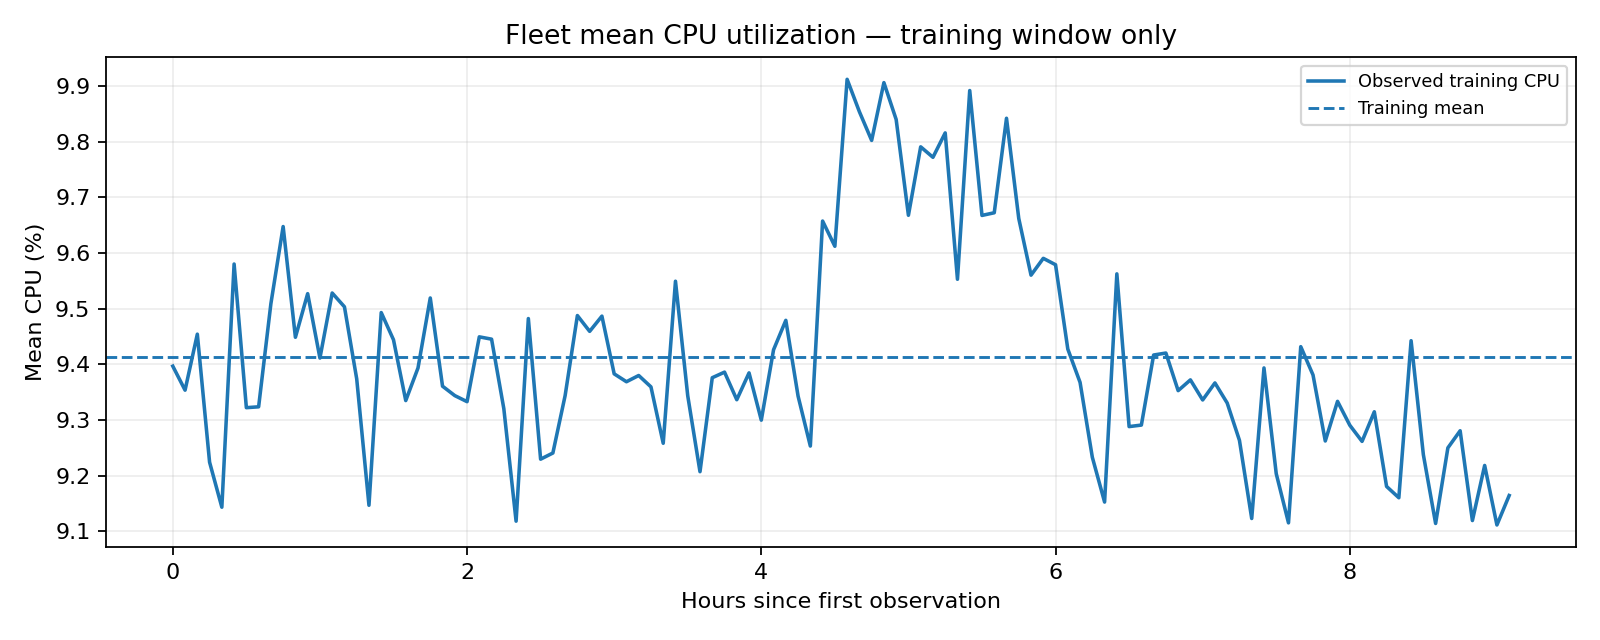

02_vm_cpu_distribution.png


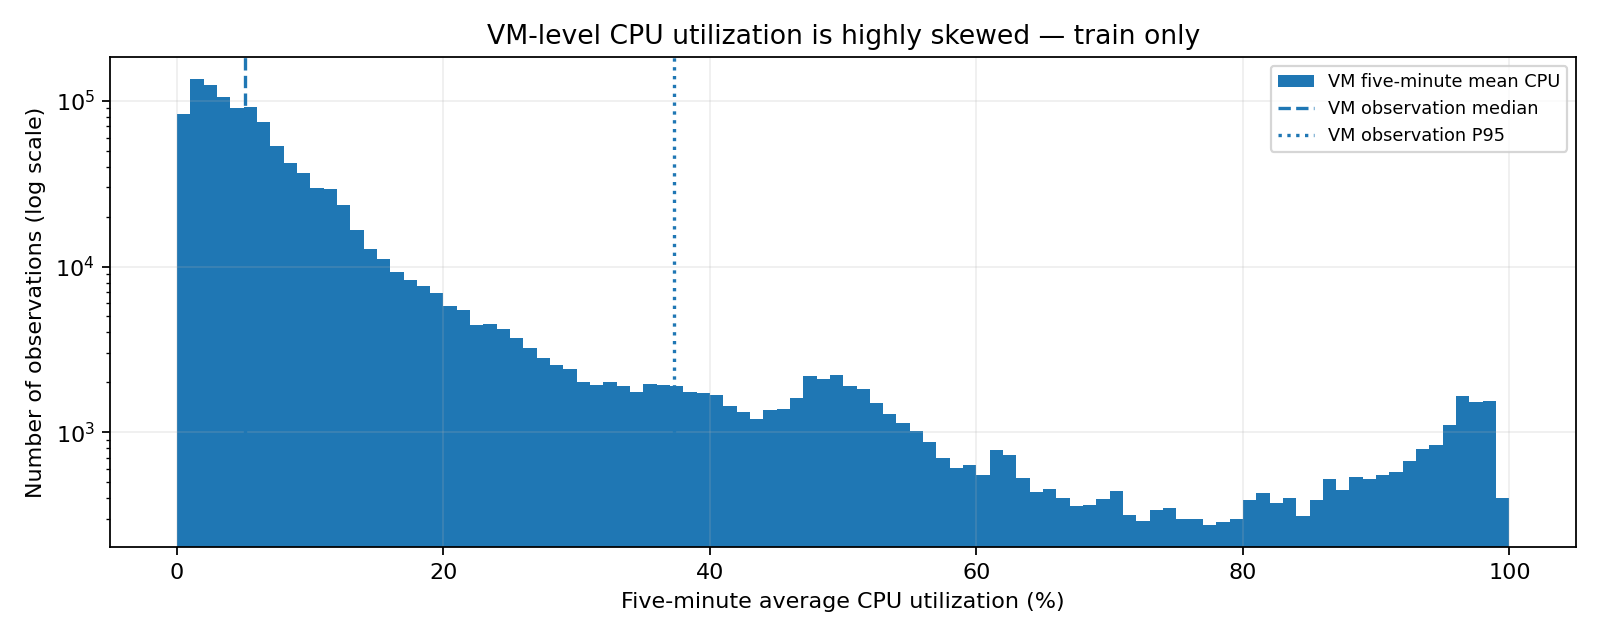

03_cpu_by_category.png


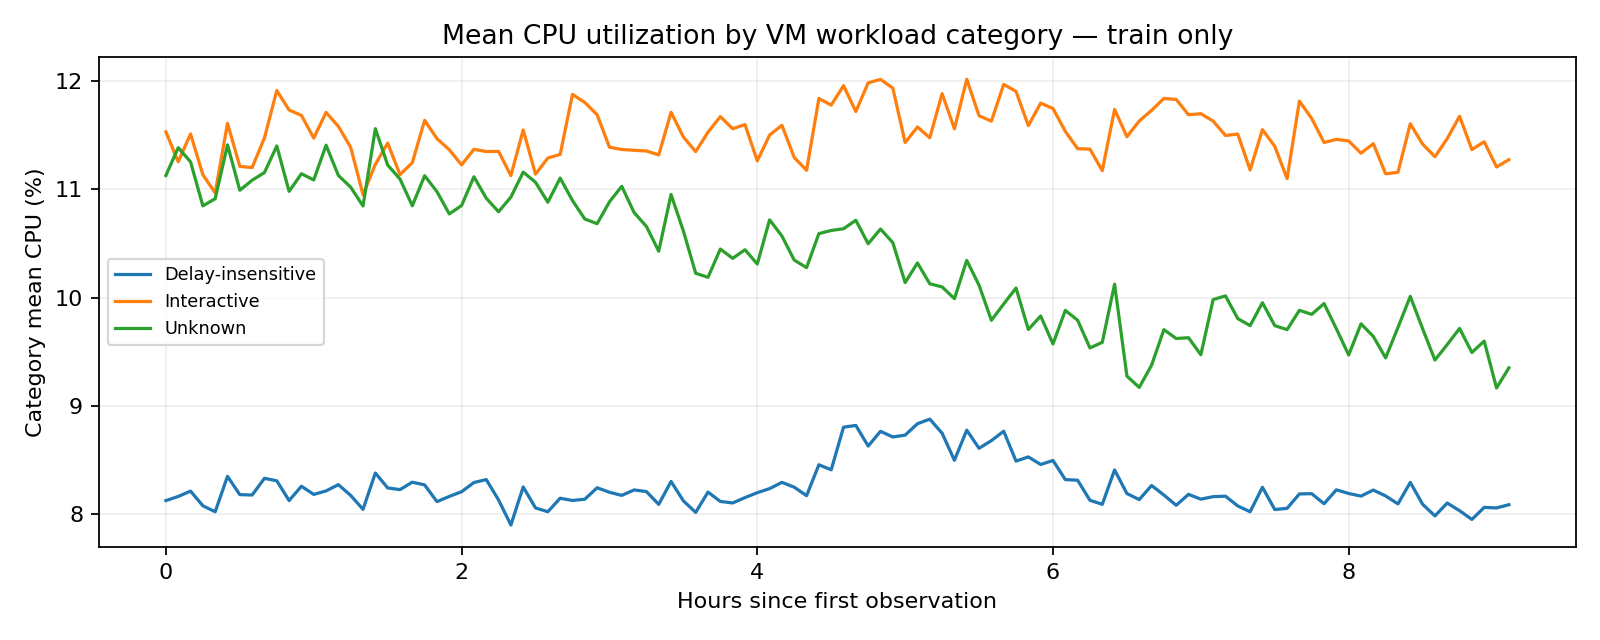

04_hot_vm_fraction.png


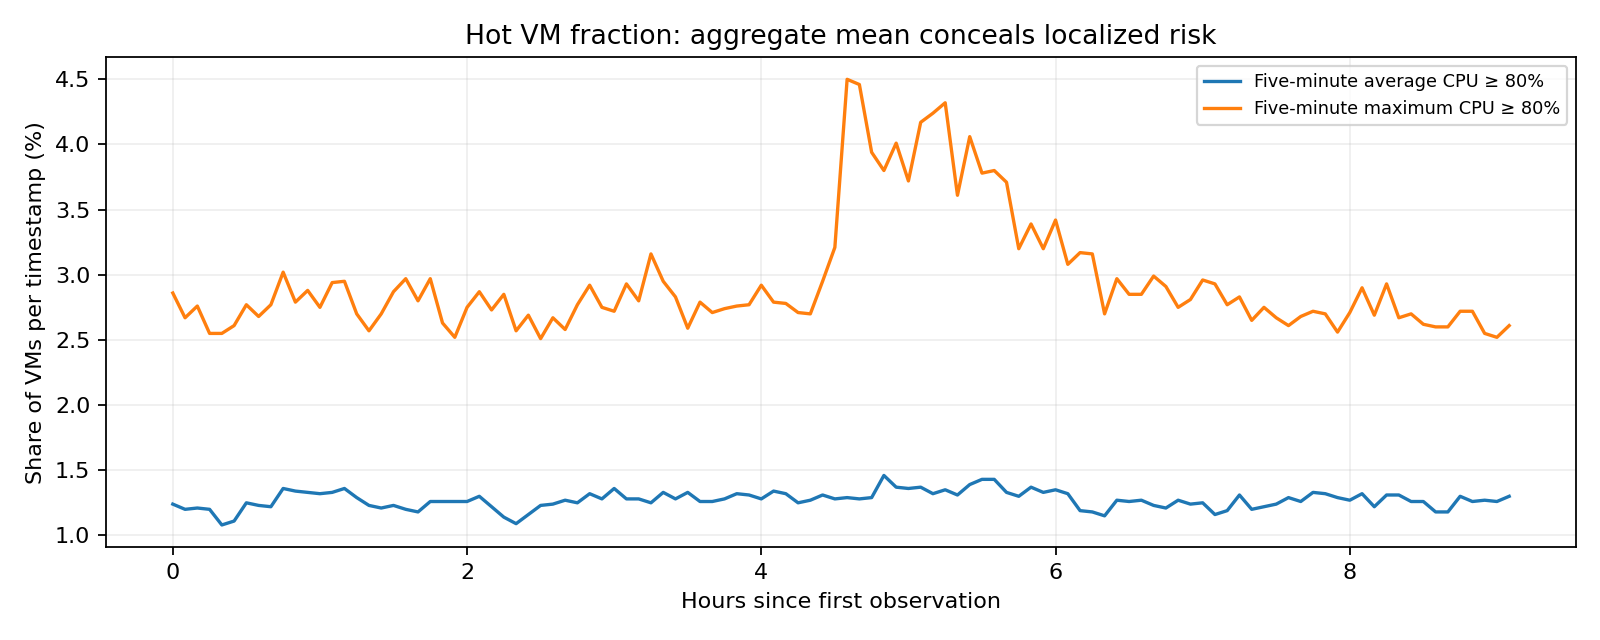

05_vm_mean_load.png


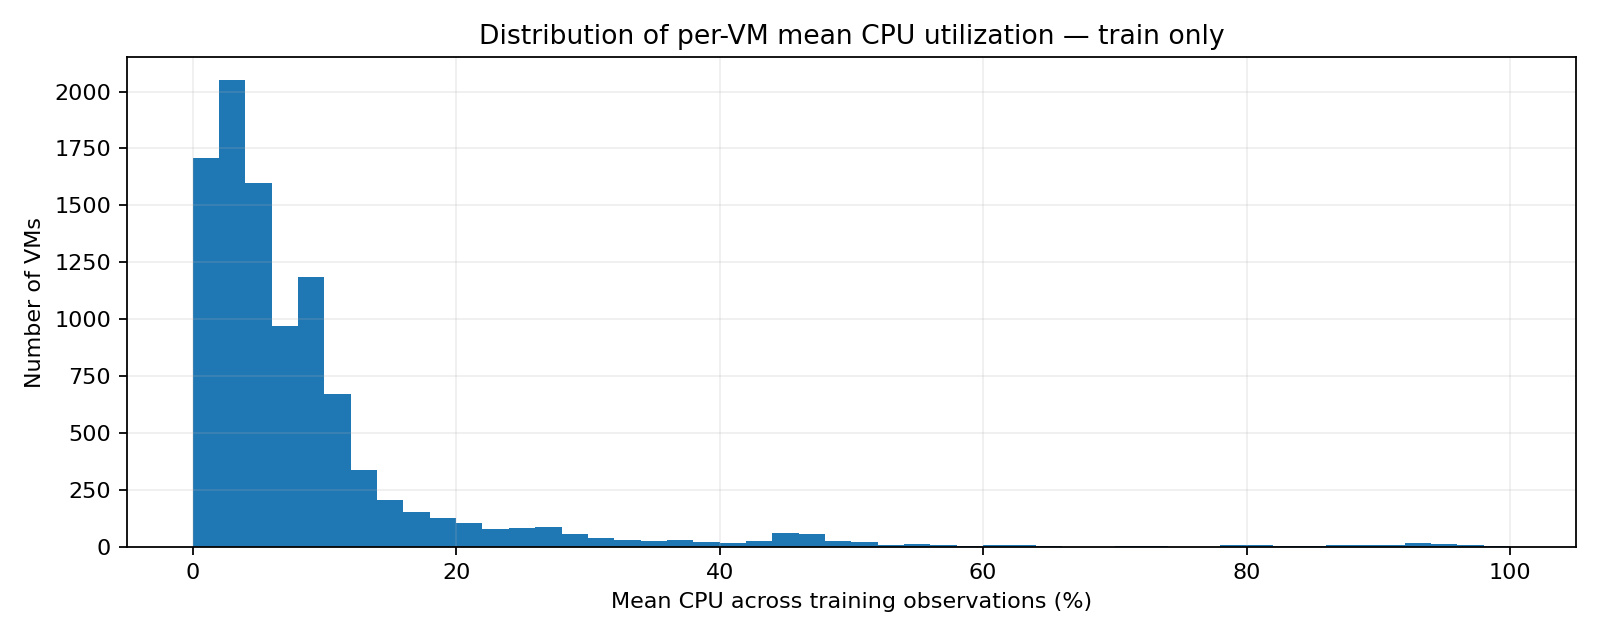

In [3]:
write_eda(bundle, ROOT / 'reports')
figures = [
    '01_aggregate_cpu_train.png',
    '02_vm_cpu_distribution.png',
    '03_cpu_by_category.png',
    '04_hot_vm_fraction.png',
    '05_vm_mean_load.png',
]
for filename in figures:
    print(filename)
    display(Image(filename=str(ROOT / 'reports' / 'figures' / filename), width=820))

## 4 — Workload segmentation

Only category and bucketed hardware attributes from metadata are used: no whole-trace CPU summary statistics or VM deletion times.

In [4]:
category_summary = pd.DataFrame(stats['categories']).T
category_summary.index.name = 'vm_category'
display(category_summary.style.format({
    'vm_share': '{:.1%}', 'mean_cpu': '{:.2f}', 'median_cpu': '{:.2f}',
    'p90_cpu': '{:.2f}', 'share_vm_readings_avg_cpu_ge_80': '{:.2%}'}))
display(by_core)

,vms,vm_share,mean_cpu,median_cpu,p90_cpu,share_vm_readings_avg_cpu_ge_80
vm_category,,,,,,
Delay-insensitive,6180.000000,61.8%,8.26,5.16,15.44,0.89%
Interactive,3091.000000,30.9%,11.51,5.30,28.54,1.91%
Unknown,729.000000,7.3%,10.35,3.42,31.26,1.78%


,vm_count,mean_cpu
virtual_core_bucket,,
2,7534,9.764163
4,1908,7.918723
8,486,9.658399
24,62,11.428831
>24,10,6.619469


## 5 — Operational interpretation

1. **The training cohort has fixed activity:** `active_vm_count` is constant because the release intentionally samples VMs with complete histories. This is a property of the curated dataset, not of Azure capacity in general.
2. **The unweighted fleet mean is not a capacity measure:** VMs have different core buckets. Without exact per-VM capacity and placement, we cannot translate a 9% average directly into spare CPU cores.
3. **Hot VMs matter:** the VM-level distribution has a long right tail, including VMs with high five-minute mean or peak CPU while the fleet average stays low. Capacity planning must consider local saturation and workload classes as separate signals.
4. **Do not infer seasonality:** roughly nine hours of training data cannot substantiate daily/weekly patterns. Only relative timestamps are provided.
5. **Completed modeling:** nine fixed candidates were compared at origins 50/62/74/86. Persistence was selected for both targets. See [`../reports/final_report.md`](../reports/final_report.md) for validation metrics and failure analysis. The script-generated reports are the authoritative current evidence.

The complete numerical findings are documented in [`../reports/eda_summary.md`](../reports/eda_summary.md).